In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
df =pd.read_csv('sleep_debt_screen_time.csv')

In [27]:
df.head()

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,0,...,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,1,...,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,1,...,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,0,...,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,1,...,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild


In [28]:
df["blue_light_filter_on"] = df["blue_light_filter_on"].astype(int)
df.head()

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,0,...,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,1,...,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,1,...,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,0,...,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,1,...,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild


In [29]:
categorical_variable = df.columns[df.dtypes == 'object'].drop('sleep_debt_category').tolist()
categorical_variable

['gender', 'chronotype', 'occupation', 'primary_app_category']

In [30]:
numerical_variable = df.columns[df.dtypes != 'object'].drop('next_day_fatigue_score').tolist()
numerical_variable

['user_id',
 'age',
 'bedtime_hour',
 'screen_time_before_bed_min',
 'screen_brightness_pct',
 'blue_light_filter_on',
 'caffeine_intake_mg',
 'caffeine_last_hour',
 'physical_activity_min',
 'room_temperature_f',
 'ambient_noise_db',
 'sleep_onset_latency_min',
 'total_sleep_hours',
 'rem_sleep_pct',
 'deep_sleep_pct',
 'awakenings_count',
 'sleep_efficiency_pct']

<Axes: xlabel='next_day_fatigue_score', ylabel='Count'>

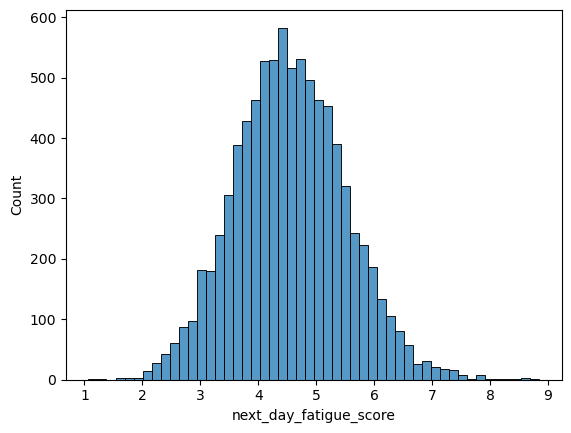

In [32]:
sns.histplot(df.next_day_fatigue_score, bins=50)

In [33]:
df.isnull().sum()

user_id                       0
age                           0
gender                        0
chronotype                    0
occupation                    0
bedtime_hour                  0
screen_time_before_bed_min    0
primary_app_category          0
screen_brightness_pct         0
blue_light_filter_on          0
caffeine_intake_mg            0
caffeine_last_hour            0
physical_activity_min         0
room_temperature_f            0
ambient_noise_db              0
sleep_onset_latency_min       0
total_sleep_hours             0
rem_sleep_pct                 0
deep_sleep_pct                0
awakenings_count              0
sleep_efficiency_pct          0
next_day_fatigue_score        0
sleep_debt_category           0
dtype: int64

In [59]:
df.sleep_debt_category.value_counts(normalize=True)

sleep_debt_category
Mild        0.516824
Moderate    0.277765
No Debt     0.202471
Severe      0.002941
Name: proportion, dtype: float64

In [36]:
for col in categorical_variable:
    print(col)
    print(df[col].unique())
    print(df[col].nunique())
    print()

gender
['Female' 'Male' 'Non-Binary']
3

chronotype
['Intermediate' 'Night Owl' 'Early Bird']
3

occupation
['Student' 'Professional' 'Retired' 'Unemployed' 'Freelancer']
5

primary_app_category
['Social Media' 'Short-Form Video' 'Messaging' 'Streaming' 'E-Reading'
 'Gaming' 'News']
7



In [61]:
mean_next_day_fatigue_score = df.next_day_fatigue_score.mean()
mean_next_day_fatigue_score

4.54989294117647

In [63]:
for c in categorical_variable:
    print(c)
    df_group = df.groupby(c).next_day_fatigue_score.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - mean_next_day_fatigue_score
    df_group['risk'] = df_group['mean'] / mean_next_day_fatigue_score
    display(df_group)
    print()
    print()


c= 'blue_light_filter_on'
print(c)
df_group = df.groupby(c).next_day_fatigue_score.agg(['mean', 'count'])
df_group['diff'] = df_group['mean'] - mean_next_day_fatigue_score
df_group['risk'] = df_group['mean'] / mean_next_day_fatigue_score
display(df_group)
print()
print()
    

gender


,mean,count,diff,risk
gender,,,,
Female,4.547319,4106,-0.002574,0.999434
Male,4.545529,4048,-0.004364,0.999041
Non-Binary,4.631503,346,0.081610,1.017937




chronotype


,mean,count,diff,risk
chronotype,,,,
Early Bird,4.370334,2067,-0.179559,0.960536
Intermediate,4.516004,3466,-0.033889,0.992552
Night Owl,4.714574,2967,0.164681,1.036194




occupation


,mean,count,diff,risk
occupation,,,,
Freelancer,4.532763,1256,-0.017130,0.996235
Professional,4.533403,2980,-0.016490,0.996376
Retired,4.609540,847,0.059647,1.013109
Student,4.553056,2588,0.003163,1.000695
Unemployed,4.564306,829,0.014413,1.003168




primary_app_category


,mean,count,diff,risk
primary_app_category,,,,
E-Reading,4.037089,711,-0.512804,0.887293
Gaming,4.671236,882,0.121343,1.026669
Messaging,4.455910,753,-0.093983,0.979344
News,4.421138,659,-0.128755,0.971702
Short-Form Video,4.745357,2468,0.195464,1.042960
Social Media,4.611298,1834,0.061405,1.013496
Streaming,4.397485,1193,-0.152408,0.966503




blue_light_filter_on


,mean,count,diff,risk
blue_light_filter_on,,,,
0,4.641481,5563,0.091588,1.020130
1,4.376415,2937,-0.173478,0.961872


In [64]:
from sklearn.metrics import mutual_info_score

In [73]:
def mutual_info_next_day_fatigue(series):
    return mutual_info_score(series, df.next_day_fatigue_score)

def mutual_info_sleep_debt_category(series):
    return mutual_info_score(series, df.sleep_debt_category)


In [74]:
mi = df[categorical_variable].apply(mutual_info_sleep_debt_category)
mi.sort_values(ascending=False)

chronotype              0.048228
primary_app_category    0.002946
occupation              0.000716
gender                  0.000326
dtype: float64

In [78]:
df[numerical_variable].corrwith(df.next_day_fatigue_score).abs().sort_values(ascending=False)

total_sleep_hours             0.688568
sleep_efficiency_pct          0.536935
sleep_onset_latency_min       0.479315
awakenings_count              0.440525
rem_sleep_pct                 0.337327
screen_time_before_bed_min    0.336067
age                           0.278334
caffeine_intake_mg            0.261541
deep_sleep_pct                0.190759
screen_brightness_pct         0.176128
blue_light_filter_on          0.132120
bedtime_hour                  0.132016
caffeine_last_hour            0.131273
ambient_noise_db              0.067587
physical_activity_min         0.016990
user_id                       0.013405
room_temperature_f            0.011141
dtype: float64

In [38]:
from sklearn.model_selection import train_test_split

In [39]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [41]:
y_train_numerical = df_train.next_day_fatigue_score.values
y_val_numerical = df_val.next_day_fatigue_score.values
y_test_numerical = df_test.next_day_fatigue_score.values
y_train_categorical = df_train.sleep_debt_category.values
y_val_categorical = df_val.sleep_debt_category.values
y_test_categorical = df_test.sleep_debt_category.values

In [57]:
df_train = df_train.drop(labels=['next_day_fatigue_score','sleep_debt_category'],axis=1)
df_val = df_val.drop(labels=['next_day_fatigue_score','sleep_debt_category'],axis=1)
df_test = df_test.drop(labels=['next_day_fatigue_score','sleep_debt_category'],axis=1)

In [58]:
df_train.head()

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,caffeine_last_hour,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct
6853,6854,16,Female,Night Owl,Professional,1.85,41,Social Media,96,1,...,21.7,14,71.6,26.2,34.4,6.73,15.7,19.2,5,75.8
3314,3315,24,Non-Binary,Early Bird,Student,22.31,45,Social Media,51,1,...,10.9,56,71.9,40.5,24.3,8.67,16.8,17.6,4,80.9
8113,8114,16,Male,Intermediate,Professional,23.38,43,Social Media,84,0,...,18.5,53,71.3,34.0,25.7,7.10,20.3,15.7,2,77.5
816,817,30,Female,Early Bird,Professional,22.47,64,Short-Form Video,51,0,...,17.9,11,68.4,35.0,36.2,6.87,10.6,14.7,3,80.4
771,772,22,Female,Early Bird,Professional,22.07,46,Messaging,67,1,...,13.2,22,75.1,41.1,25.5,7.93,17.5,16.5,0,85.7


In [79]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder

In [102]:
scaler = StandardScaler()
#scaler = MinMaxScaler()

X_train_num = scaler.fit_transform(df_train[numerical_variable].values)
X_val_num = scaler.transform(df_val[numerical_variable].values)

In [147]:
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_train_cat = ohe.fit_transform(df_train[categorical_variable].values)
X_val_cat   = ohe.transform(df_val[categorical_variable].values)

In [90]:
ohe.get_feature_names_out()

array(['x0_Female', 'x0_Male', 'x0_Non-Binary', 'x1_Early Bird',
       'x1_Intermediate', 'x1_Night Owl', 'x2_Freelancer',
       'x2_Professional', 'x2_Retired', 'x2_Student', 'x2_Unemployed',
       'x3_E-Reading', 'x3_Gaming', 'x3_Messaging', 'x3_News',
       'x3_Short-Form Video', 'x3_Social Media', 'x3_Streaming'],
      dtype=object)

In [91]:
X_train = np.column_stack([X_train_num, X_train_cat])
X_val = np.column_stack([X_val_num, X_val_cat])

In [94]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

In [96]:
lr = LinearRegression()

lr.fit(X_train, y_train_numerical)

y_pred = lr.predict(X_val)

root_mean_squared_error(y_val_numerical, y_pred)

0.41792753128097043

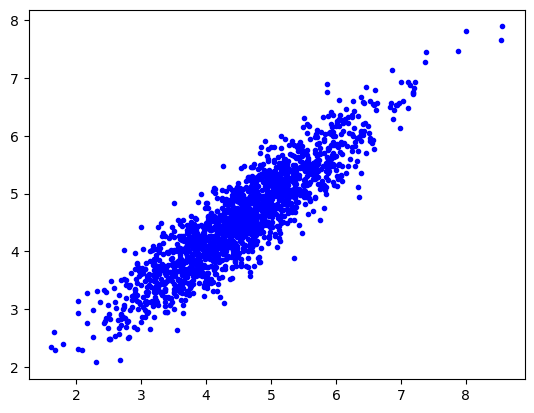

In [101]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [103]:


X_train_num = df_train[numerical_variable].values
X_val_num = df_val[numerical_variable].values

X_train = np.column_stack([X_train_num, X_train_cat])
X_val = np.column_stack([X_val_num, X_val_cat])

lr = LinearRegression()
lr.fit(X_train, y_train_numerical)
y_pred = lr.predict(X_val)
root_mean_squared_error(y_val_numerical, y_pred)

0.4179289887988112

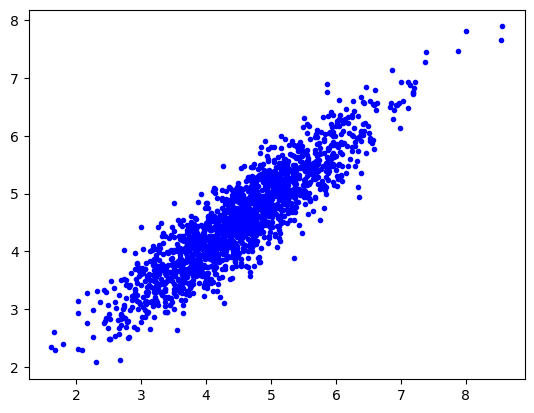

In [104]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [113]:
#scaler = StandardScaler()
sacler = MinMaxScaler()

X_train_num = scaler.fit_transform(df_train[numerical_variable].values)
X_val_num = scaler.transform(df_val[numerical_variable].values)

X_train = np.column_stack([X_train_num, X_train_cat])
X_val = np.column_stack([X_val_num, X_val_cat])

lr = LinearRegression()
lr.fit(X_train, y_train_numerical)
y_pred = lr.predict(X_val)
root_mean_squared_error(y_val_numerical, y_pred)

0.41792753128097043

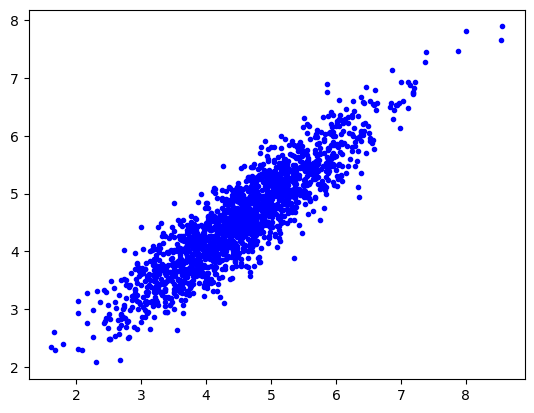

In [114]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [108]:
from sklearn 

In [109]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical_variable + numerical_variable].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical_variable + numerical_variable].to_dict(orient='records')
X_val = dv.transform(val_dict)

lr = LinearRegression()
lr.fit(X_train, y_train_numerical)
y_pred = lr.predict(X_val)
root_mean_squared_error(y_val_numerical, y_pred)

0.41792898879880774

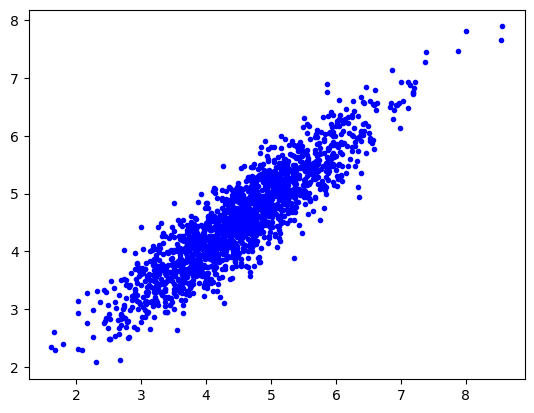

In [110]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [148]:
scaler = StandardScaler()

X_train_num = scaler.fit_transform(df_train[numerical_variable].values)
X_val_num = scaler.transform(df_val[numerical_variable].values)

X_train = np.column_stack([X_train_num, X_train_cat])
X_val = np.column_stack([X_val_num, X_val_cat])

lr = LinearRegression()
lr.fit(X_train, y_train_numerical)
y_pred = lr.predict(X_val)
root_mean_squared_error(y_val_numerical, y_pred)

0.41792753128097043

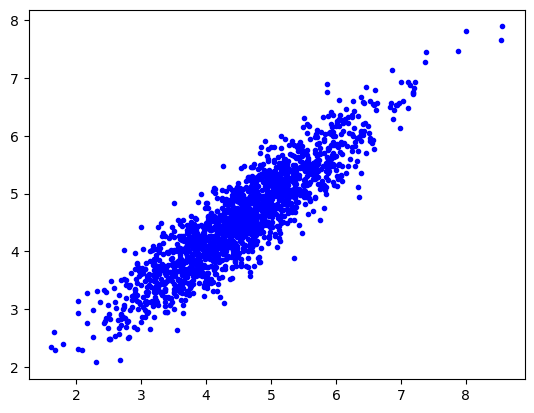

In [149]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [150]:
lr.coef_

array([ 6.60482524e-03,  8.53061666e-03,  1.59535436e-02,  1.37922375e-01,
        7.37132542e-02, -7.33452981e-02,  5.91311781e-02,  3.96978277e-02,
       -2.25596489e-03, -2.11906929e-03, -1.06641041e-02,  3.77292151e-02,
       -5.96927612e-01, -1.10727183e-01, -5.92712970e-03,  2.42117160e-01,
       -1.52897332e-01,  1.26426800e+10,  1.26426800e+10,  1.26426800e+10,
        4.84995691e+10,  4.84995691e+10,  4.84995691e+10,  9.80718200e+09,
        9.80718200e+09,  9.80718200e+09,  9.80718200e+09,  9.80718200e+09,
       -2.22070160e+10, -2.22070160e+10, -2.22070160e+10, -2.22070160e+10,
       -2.22070160e+10, -2.22070160e+10, -2.22070160e+10])

In [146]:
from sklearn.linear_model import Ridge

In [152]:
for alpha in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    rid = Ridge(alpha= alpha)
    rid.fit(X_train, y_train_numerical)
    y_pred = rid.predict(X_val)
    print (f'alpha={alpha}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')

alpha=0.0001, rmse=0.41792898883376145
alpha=0.001, rmse=0.41792898914846294
alpha=0.01, rmse=0.4179289923106396
alpha=0.1, rmse=0.41792902544783506
alpha=1, rmse=0.4179295075912121
alpha=10, rmse=0.41794866785677626
alpha=100, rmse=0.4190694340842815


In [153]:
rid.coef_

array([ 0.00639123,  0.01370909,  0.0111304 ,  0.13106693,  0.06978056,
       -0.06936508,  0.05118532,  0.0351256 , -0.00135756, -0.00407279,
       -0.01273561,  0.05733935, -0.57877512, -0.11958719, -0.00597596,
        0.23592739, -0.15294248, -0.00449864, -0.01580083,  0.02029947,
       -0.00425478, -0.0052352 ,  0.00948998,  0.00829017, -0.01117025,
        0.0013674 , -0.00700831,  0.00852099, -0.24808146,  0.10213932,
       -0.00895751, -0.06721157,  0.16373171,  0.08568551, -0.027306  ])

In [215]:
categorical_variable = df.columns[df.dtypes == 'object'].drop('sleep_debt_category').tolist()
categorical_variable.remove('gender')
categorical_variable.remove('occupation')
categorical_variable

['chronotype', 'primary_app_category']

In [237]:
numerical_variable = list(df[df.columns[df.dtypes != 'object'].drop('next_day_fatigue_score').tolist()].corrwith(df.next_day_fatigue_score).abs().sort_values(ascending=False).index[:14])
numerical_variable

['total_sleep_hours',
 'sleep_efficiency_pct',
 'sleep_onset_latency_min',
 'awakenings_count',
 'rem_sleep_pct',
 'screen_time_before_bed_min',
 'age',
 'caffeine_intake_mg',
 'deep_sleep_pct',
 'screen_brightness_pct',
 'blue_light_filter_on',
 'bedtime_hour',
 'caffeine_last_hour',
 'ambient_noise_db']

In [238]:
scaler = StandardScaler()

X_train_num = scaler.fit_transform(df_train[numerical_variable].values)
X_val_num = scaler.transform(df_val[numerical_variable].values)

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_train_cat = ohe.fit_transform(df_train[categorical_variable].values)
X_val_cat   = ohe.transform(df_val[categorical_variable].values)

X_train = np.column_stack([X_train_num, X_train_cat])
X_val = np.column_stack([X_val_num, X_val_cat])



In [239]:
for alpha in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    rid = Ridge(alpha= alpha)
    rid.fit(X_train, y_train_numerical)
    y_pred = rid.predict(X_val)
    print (f'alpha={alpha}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')

alpha=0.0001, rmse=0.41830717879413304
alpha=0.001, rmse=0.4183071792955611
alpha=0.01, rmse=0.4183071843247867
alpha=0.1, rmse=0.41830723611072196
alpha=1, rmse=0.41830790258151973
alpha=10, rmse=0.41832870418790835
alpha=100, rmse=0.4194543374707009


In [250]:
alpha=1
rid = Ridge(alpha= alpha)
rid.fit(X_train, y_train_numerical)
y_pred = rid.predict(X_val)
print (f'alpha={alpha}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')
rid.coef_

alpha=1, rmse=0.41830790258151973


array([-0.59627061, -0.15326106,  0.03724108,  0.24214421, -0.11070564,
        0.13811925,  0.0089368 ,  0.05912258, -0.00695468,  0.07367106,
       -0.07370745,  0.01582862,  0.03966964, -0.01068304, -0.00095222,
       -0.00525283,  0.00620504, -0.3242991 ,  0.13716462, -0.00367724,
       -0.08439618,  0.19700355,  0.10708151, -0.02887716])

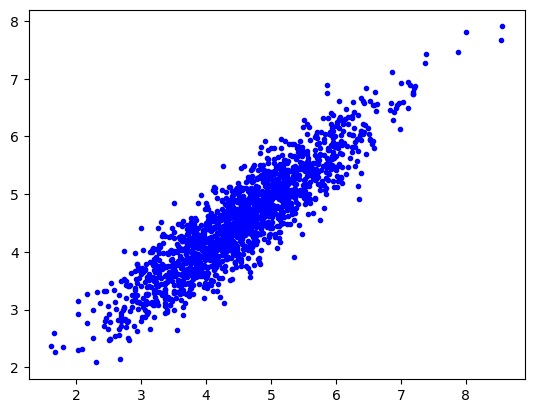

In [243]:
plt.plot(y_val_numerical, y_pred, 'b.', ls=' ')

In [244]:
from sklearn.linear_model import Lasso

In [245]:
for alpha in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    las = Lasso(alpha= alpha)
    las.fit(X_train, y_train_numerical)
    y_pred = las.predict(X_val)
    print (f'alpha={alpha}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')

alpha=0.0001, rmse=0.41829040478654866
alpha=0.001, rmse=0.4182532146607659
alpha=0.01, rmse=0.4247442489473157
alpha=0.1, rmse=0.47387087622733226
alpha=1, rmse=0.9653325639386586
alpha=10, rmse=0.9653325639386586
alpha=100, rmse=0.9653325639386586


In [247]:
for alpha in [0.0001, 0.00025, 0.0005, 0.001, 0.0025, 0.005, 0.01]:
    las = Lasso(alpha= alpha)
    las.fit(X_train, y_train_numerical)
    y_pred = las.predict(X_val)
    print (f'alpha={alpha}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')

alpha=0.0001, rmse=0.41829040478654866
alpha=0.00025, rmse=0.4182701853234137
alpha=0.0005, rmse=0.4182487547476989
alpha=0.001, rmse=0.4182532146607659
alpha=0.0025, rmse=0.41861099100319177
alpha=0.005, rmse=0.41997724208707793
alpha=0.01, rmse=0.4247442489473157


In [251]:
alpha=0.0005
las = Lasso(alpha= alpha)
las.fit(X_train, y_train_numerical)
y_pred = las.predict(X_val)
print (f'alpha={alpha}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')
las.coef_

alpha=0.0005, rmse=0.4182487547476989


array([-0.59629436, -0.15324674,  0.03936717,  0.24172005, -0.11209943,
        0.13697363,  0.00781725,  0.05756203, -0.00658364,  0.07283378,
       -0.07281282,  0.01328297,  0.03858898, -0.01047226,  0.        ,
       -0.00412272,  0.00174448, -0.31192158,  0.13474159, -0.        ,
       -0.07374372,  0.19663839,  0.10733425, -0.02121554])

In [252]:
from sklearn.linear_model import ElasticNet

In [255]:
for alpha in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    print(alpha)
    for l1_ratio in range(11):
        elnet = ElasticNet(alpha= alpha, l1_ratio=l1_ratio/10)
        elnet.fit(X_train, y_train_numerical)
        y_pred = elnet.predict(X_val)
        print (f'alpha={alpha}, l1_ratio={l1_ratio}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')
    print()

0.0001


C:\Users\a1043649\AppData\Local\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:678: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.208e+02, tolerance: 4.584e-01 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


alpha=0.0001, l1_ratio=0, rmse=0.4183075968064738


C:\Users\a1043649\AppData\Local\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:678: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.300e+01, tolerance: 4.584e-01
  model = cd_fast.enet_coordinate_descent(


alpha=0.0001, l1_ratio=1, rmse=0.4183052859456404
alpha=0.0001, l1_ratio=2, rmse=0.41830380344205065
alpha=0.0001, l1_ratio=3, rmse=0.4183020794018205
alpha=0.0001, l1_ratio=4, rmse=0.41830033754882295
alpha=0.0001, l1_ratio=5, rmse=0.41829860193903984
alpha=0.0001, l1_ratio=6, rmse=0.4182969236860598
alpha=0.0001, l1_ratio=7, rmse=0.4182952493285065
alpha=0.0001, l1_ratio=8, rmse=0.41829358326725025
alpha=0.0001, l1_ratio=9, rmse=0.41829197802585627
alpha=0.0001, l1_ratio=10, rmse=0.41829040478654866

0.001


C:\Users\a1043649\AppData\Local\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:678: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.224e+02, tolerance: 4.584e-01 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


... (6 outputs left out)

alpha=1, l1_ratio=0, rmse=0.5408617015106627
alpha=1, l1_ratio=1, rmse=0.6071667106771612
alpha=1, l1_ratio=2, rmse=0.6800925135967456
alpha=1, l1_ratio=3, rmse=0.7579634273116461
alpha=1, l1_ratio=4, rmse=0.8337629573405773
alpha=1, l1_ratio=5, rmse=0.8982281501454966
alpha=1, l1_ratio=6, rmse=0.9390249805721219
alpha=1, l1_ratio=7, rmse=0.9653325639386586
alpha=1, l1_ratio=8, rmse=0.9653325639386586
alpha=1, l1_ratio=9, rmse=0.9653325639386586
alpha=1, l1_ratio=10, rmse=0.9653325639386586

10


C:\Users\a1043649\AppData\Local\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:678: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.981e+03, tolerance: 4.584e-01 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


alpha=10, l1_ratio=0, rmse=0.8363776925083491
alpha=10, l1_ratio=1, rmse=0.9653325639386586
alpha=10, l1_ratio=2, rmse=0.9653325639386586
alpha=10, l1_ratio=3, rmse=0.9653325639386586
alpha=10, l1_ratio=4, rmse=0.9653325639386586
alpha=10, l1_ratio=5, rmse=0.9653325639386586
alpha=10, l1_ratio=6, rmse=0.9653325639386586
alpha=10, l1_ratio=7, rmse=0.9653325639386586
alpha=10, l1_ratio=8, rmse=0.9653325639386586
alpha=10, l1_ratio=9, rmse=0.9653325639386586
alpha=10, l1_ratio=10, rmse=0.9653325639386586

100
alpha=100, l1_ratio=0, rmse=0.9492788921933902
alpha=100, l1_ratio=1, rmse=0.9653325639386586
alpha=100, l1_ratio=2, rmse=0.9653325639386586
alpha=100, l1_ratio=3, rmse=0.9653325639386586
alpha=100, l1_ratio=4, rmse=0.9653325639386586
alpha=100, l1_ratio=5, rmse=0.9653325639386586
alpha=100, l1_ratio=6, rmse=0.9653325639386586
alpha=100, l1_ratio=7, rmse=0.9653325639386586
alpha=100, l1_ratio=8, rmse=0.9653325639386586
alpha=100, l1_ratio=9, rmse=0.9653325639386586
alpha=100, l1_rati

C:\Users\a1043649\AppData\Local\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:678: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.254e+03, tolerance: 4.584e-01 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


In [270]:
for alpha in [0.0005, 0.001, 0.002]:
    print(alpha)
    for l1_ratio in [7, 7.5, 8, 8.5, 9]:
        elnet = ElasticNet(alpha= alpha, l1_ratio=l1_ratio/10)
        elnet.fit(X_train, y_train_numerical)
        y_pred = elnet.predict(X_val)
        print (f'alpha={alpha}, l1_ratio={l1_ratio}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')
    print()

0.0005
alpha=0.0005, l1_ratio=7, rmse=0.41826171716654864
alpha=0.0005, l1_ratio=7.5, rmse=0.418259415544533
alpha=0.0005, l1_ratio=8, rmse=0.4182569668829348
alpha=0.0005, l1_ratio=8.5, rmse=0.4182547631225988
alpha=0.0005, l1_ratio=9, rmse=0.4182526210278419

0.001
alpha=0.001, l1_ratio=7, rmse=0.41824984081053074
alpha=0.001, l1_ratio=7.5, rmse=0.41824956267016844
alpha=0.001, l1_ratio=8, rmse=0.4182494440861585
alpha=0.001, l1_ratio=8.5, rmse=0.4182498804021947
alpha=0.001, l1_ratio=9, rmse=0.4182504811428708

0.002
alpha=0.002, l1_ratio=7, rmse=0.4183220469263278
alpha=0.002, l1_ratio=7.5, rmse=0.4183360577530479
alpha=0.002, l1_ratio=8, rmse=0.4183533763716932
alpha=0.002, l1_ratio=8.5, rmse=0.41837216258422855
alpha=0.002, l1_ratio=9, rmse=0.41839263565936075



In [271]:
alpha = 0.001
l1_ratio=8
elnet = ElasticNet(alpha= alpha, l1_ratio=l1_ratio/10)
elnet.fit(X_train, y_train_numerical)
y_pred = elnet.predict(X_val)
print (f'alpha={alpha}, l1_ratio={l1_ratio}, rmse={root_mean_squared_error(y_val_numerical, y_pred)}')

elnet.coef_

alpha=0.001, l1_ratio=8, rmse=0.4182494440861585


array([-0.5959275 , -0.15323478,  0.04105004,  0.24135671, -0.11313441,
        0.13614905,  0.00726168,  0.05645238, -0.00635271,  0.0722538 ,
       -0.07220834,  0.01202146,  0.03784465, -0.01040017,  0.        ,
       -0.00335814,  0.        , -0.30491228,  0.13051598, -0.        ,
       -0.06909692,  0.19372118,  0.10499952, -0.01866673])

In [272]:
from sklearn.model_selection import GridSearchCV


In [283]:
parameters = {'alpha':[0.0001, 0.00025, 0.0005, 0.001, 0.002], 'l1_ratio':[0.7+i/20 for i in range(7)]}
elnet =ElasticNet()
clf = GridSearchCV(elnet, parameters, scoring='neg_root_mean_squared_error')
clf.fit(X_train, y_train_numerical)
print(clf.best_params_)
print(-clf.best_score_)

{'alpha': 0.0005, 'l1_ratio': 1.0}
0.40787611124516454


In [285]:
from sklearn.tree import DecisionTreeRegressor

In [292]:
scores =[]

for max_d in range(1,21):
    score =[]
    for min_sl in [1, 5, 10, 15, 20, 500, 100, 200]:
        dt = DecisionTreeRegressor(max_depth=max_d, min_samples_leaf=min_sl)
        dt.fit(X_train, y_train_numerical)
        y_pred = dt.predict(X_val)
        score.append(root_mean_squared_error(y_val_numerical, y_pred))
        print (f'max_depth={max_d}, min_sample_leaf={min_sl}, rmse={score[-1]}')
    scores.append(score)

scores

max_depth=1, min_sample_leaf=1, rmse=0.8152289218938082
max_depth=1, min_sample_leaf=5, rmse=0.8152289218938084
max_depth=1, min_sample_leaf=10, rmse=0.8152289218938085
max_depth=1, min_sample_leaf=15, rmse=0.8152289218938084
max_depth=1, min_sample_leaf=20, rmse=0.8152289218938084
max_depth=1, min_sample_leaf=500, rmse=0.8152289218938084
max_depth=1, min_sample_leaf=100, rmse=0.8152289218938084
max_depth=1, min_sample_leaf=200, rmse=0.8152289218938084
max_depth=2, min_sample_leaf=1, rmse=0.7188284480687512
max_depth=2, min_sample_leaf=5, rmse=0.7188284480687513
max_depth=2, min_sample_leaf=10, rmse=0.7188284480687512
max_depth=2, min_sample_leaf=15, rmse=0.7188284480687511
max_depth=2, min_sample_leaf=20, rmse=0.7188284480687512
max_depth=2, min_sample_leaf=500, rmse=0.7188284480687511
max_depth=2, min_sample_leaf=100, rmse=0.7188284480687512
max_depth=2, min_sample_leaf=200, rmse=0.7188284480687511
max_depth=3, min_sample_leaf=1, rmse=0.6500290556873
max_depth=3, min_sample_leaf=5, r

[[0.8152289218938082,
  0.8152289218938084,
  0.8152289218938085,
  0.8152289218938084,
  0.8152289218938084,
  0.8152289218938084,
  0.8152289218938084,
  0.8152289218938084],
 [0.7188284480687512,
  0.7188284480687513,
  0.7188284480687512,
  0.7188284480687511,
  0.7188284480687512,
  0.7188284480687511,
  0.7188284480687512,
  0.7188284480687511],
 [0.6500290556873,
  0.6500290556873,
  0.6500290556873,
  0.6500290556873,
  0.6500290556873001,
  0.6625465178835541,
  0.6500290556873,
  0.6500290556873],
 [0.6009104369334793,
  0.6009104369334793,
  0.6009104369334792,
  0.6009104369334793,
  0.6009104369334792,
  0.6542518507244427,
  0.6026325296911677,
  0.6086528977667442],
 [0.5765624531416461,
  0.5765624531416461,
  0.5777110876596515,
  0.5782897184259879,
  0.5756079417711149,
  0.6542518507244429,
  0.5885091506477536,
  0.6004500728610638],
 [0.5574068194539215,
  0.5586402880456198,
  0.5570368889022304,
  0.5598397202728589,
  0.5563771050891899,
  0.6542518507244429,
 

<Axes: >

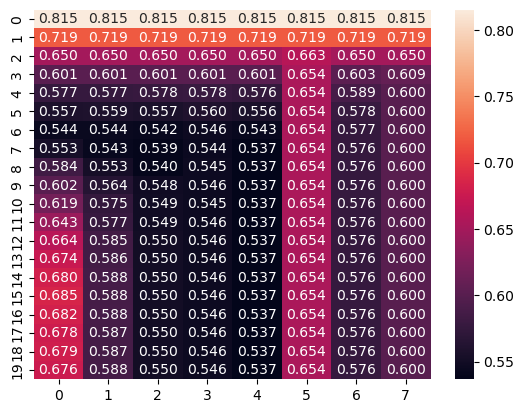

In [293]:
sns.heatmap(scores, annot=True, fmt=".3f")

In [294]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
scores =[]

for max_d in range(1,21):
    score =[]
    for n_est in [10, 20, 50, 100, 200, 500, 1000]:
        rf = RandomForestRegressor(max_depth=max_d, n_estimators=n_est)
        rf.fit(X_train, y_train_numerical)
        y_pred = rf.predict(X_val)
        score.append(root_mean_squared_error(y_val_numerical, y_pred))
        print (f'max_depth={max_d}, n_estimators={n_est}, rmse={score[-1]}')
    scores.append(score)

scores

max_depth=1, n_estimators=10, rmse=0.7957397049115853
max_depth=1, n_estimators=20, rmse=0.7992287104058188
max_depth=1, n_estimators=50, rmse=0.798594517704739
max_depth=1, n_estimators=100, rmse=0.7954485195818327
max_depth=1, n_estimators=200, rmse=0.7962430832746779
max_depth=1, n_estimators=500, rmse=0.7964370104225638
max_depth=1, n_estimators=1000, rmse=0.7955917583756018
max_depth=2, n_estimators=10, rmse=0.6808996274850282
max_depth=2, n_estimators=20, rmse=0.6846821752178033
max_depth=2, n_estimators=50, rmse=0.6867260224997151
max_depth=2, n_estimators=100, rmse=0.6823822764059151
max_depth=2, n_estimators=200, rmse=0.6823873274690009
max_depth=2, n_estimators=500, rmse=0.6831817507600135
max_depth=2, n_estimators=1000, rmse=0.6820175008844533
max_depth=3, n_estimators=10, rmse=0.6175316930324236
max_depth=3, n_estimators=20, rmse=0.6155018823253104
max_depth=3, n_estimators=50, rmse=0.6149371255541525
max_depth=3, n_estimators=100, rmse=0.6116171971788017
max_depth=3, n_est

<Axes: >

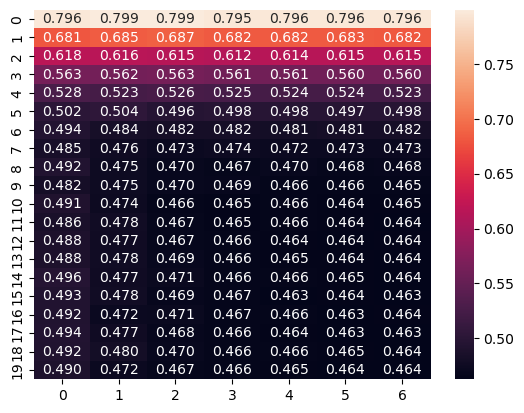

In [304]:
sns.heatmap(scores, annot=True, fmt=".3f")

In [303]:
from sklearn.kernel_ridge import KernelRidge

In [312]:
scores =[]

alpha=1
kernel = 'poly'
scoress = []
for kernel in ['linear', 'poly', 'polynomial' ]:
    scores =[]
    for gamma in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
        score =[]
        for degree in range(1,6):
            kr = KernelRidge(alpha=alpha,gamma=gamma,kernel=kernel,degree=degree)
            kr.fit(X_train, y_train_numerical)
            y_pred = kr.predict(X_val)
            score.append(root_mean_squared_error(y_val_numerical, y_pred))
            print (f'kernel={kernel}, gamma={gamma}, rmse={score[-1]}')
        scores.append(score)
    scoress.append(scores)
scores

kernel=linear, gamma=0.0001, rmse=0.4182735338806266
kernel=linear, gamma=0.0001, rmse=0.4182735338806266
kernel=linear, gamma=0.0001, rmse=0.4182735338806266
kernel=linear, gamma=0.0001, rmse=0.4182735338806266
kernel=linear, gamma=0.0001, rmse=0.4182735338806266
kernel=linear, gamma=0.001, rmse=0.4182735338806266
kernel=linear, gamma=0.001, rmse=0.4182735338806266
kernel=linear, gamma=0.001, rmse=0.4182735338806266
kernel=linear, gamma=0.001, rmse=0.4182735338806266
kernel=linear, gamma=0.001, rmse=0.4182735338806266
kernel=linear, gamma=0.01, rmse=0.4182735338806266
kernel=linear, gamma=0.01, rmse=0.4182735338806266
kernel=linear, gamma=0.01, rmse=0.4182735338806266
kernel=linear, gamma=0.01, rmse=0.4182735338806266
kernel=linear, gamma=0.01, rmse=0.4182735338806266
kernel=linear, gamma=0.1, rmse=0.4182735338806266
kernel=linear, gamma=0.1, rmse=0.4182735338806266
kernel=linear, gamma=0.1, rmse=0.4182735338806266
kernel=linear, gamma=0.1, rmse=0.4182735338806266
kernel=linear, gamma

[[0.6222842035812243,
  0.5387878945555157,
  0.5023756955183326,
  0.48219869631282164,
  0.4694477652889967],
 [0.44278313453250107,
  0.42907371266416333,
  0.42439884803199523,
  0.4219014554763352,
  0.4202438606818592],
 [0.4194189149253233,
  0.4141348029163239,
  0.41394252409106735,
  0.4147875636951049,
  0.41633701552154323],
 [0.4183093877976765,
  0.4176416201599092,
  0.4686185983016924,
  0.5979252169675677,
  1.2128338476251412],
 [0.41829561989265157,
  0.4184351469471675,
  0.5524752038372739,
  1.9370289247505679,
  3.9886534987954336],
 [0.41830402532535216,
  0.4183950040798569,
  0.561427452327722,
  2.3408645427857806,
  5.19932472977714],
 [0.41830680042893276,
  0.41839409485864215,
  0.5614403331226007,
  2.397502701722893,
  5.337386959254814]]